# 07 — Avaliação Final e Interpretação

Este é o último notebook da trilha principal. Até aqui, nós:
- exploramos os dados (01)
- treinamos o primeiro modelo (02)
- preparamos melhor os dados (03)
- trocamos para modelos não lineares (04)
- avaliamos com validação cruzada (05)
- ajustamos os hiperparâmetros (06)

O modelo escolhido é a **random forest com os atributos do notebook 03 e `max_features=0.75`**. Agora vamos fechar o projeto como num trabalho real:

1. **Avaliação final** no conjunto de teste, guardado desde o notebook 02
2. **Entender os erros**: quanto, para quais casas e onde no mapa
3. **Interpretar o modelo**: *permutation importance* e *dependência parcial*
4. **Salvar o modelo** num arquivo e carregá-lo de novo
5. **Prever o preço de casas novas**
6. Discutir as **limitações** e o uso responsável

> Lembrete: execute as células em ordem com `Shift + Enter`.

## 1. Importando bibliotecas e preparando os dados

In [1]:
import sys
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ferramentas novas deste notebook:
from sklearn.inspection import permutation_importance        # importância por embaralhamento
from sklearn.inspection import PartialDependenceDisplay      # gráficos de dependência parcial
import joblib                                                # salvar e carregar modelos

# NOVIDADE: as funções de atributos agora vêm de um arquivo do projeto, o atributos.py.
# "from atributos import ..." procura um arquivo chamado atributos.py na pasta do notebook.
# Na seção 7 você vai entender por que isso é necessário.
from atributos import criar_derivados, criar_dist_cidade

pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 100

df = fetch_california_housing(as_frame=True).frame
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

# A mesma divisão de sempre. Hoje, finalmente, vamos usar o teste!
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Treino: {len(X_train_full)} casas   Teste: {len(X_test)} casas")

Treino: 16512 casas   Teste: 4128 casas


## 2. Treinando o modelo final

🎓 **Modelo final:** depois de usar a validação cruzada para **escolher** o modelo e os hiperparâmetros, treinamos uma última vez com **todos** os dados de treino disponíveis (as 16.512 casas). As escolhas já estão feitas, então não há mais motivo para deixar dados de fora do treino. Só o teste continua de fora.

In [2]:
modelo_final = Pipeline([
    ("derivados", FunctionTransformer(criar_derivados)),
    ("dist_cidade", FunctionTransformer(criar_dist_cidade)),
    ("modelo", RandomForestRegressor(
        n_estimators=100,
        max_features=0.75,   # escolhido no notebook 06
        n_jobs=-1,
        random_state=42,
    )),
])

modelo_final.fit(X_train_full, y_train_full)
print("Modelo final treinado.")

Modelo final treinado.


## 3. Avaliação final no teste

Esta é a **prova final**. O conjunto de teste foi separado no notebook 02 e **nunca** influenciou nenhuma decisão. Avaliamos **uma única vez**, e o resultado é o que é: não voltamos atrás para ajustar nada depois de vê-lo.

In [3]:
previsoes = modelo_final.predict(X_test)

mae = mean_absolute_error(y_test, previsoes)
rmse = np.sqrt(mean_squared_error(y_test, previsoes))
r2 = r2_score(y_test, previsoes)

print(f"MAE:  {mae:.3f}   (≈ US$ {mae * 100_000:,.0f})")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")

MAE:  0.303   (≈ US$ 30,279)
RMSE: 0.467
R²:   0.833


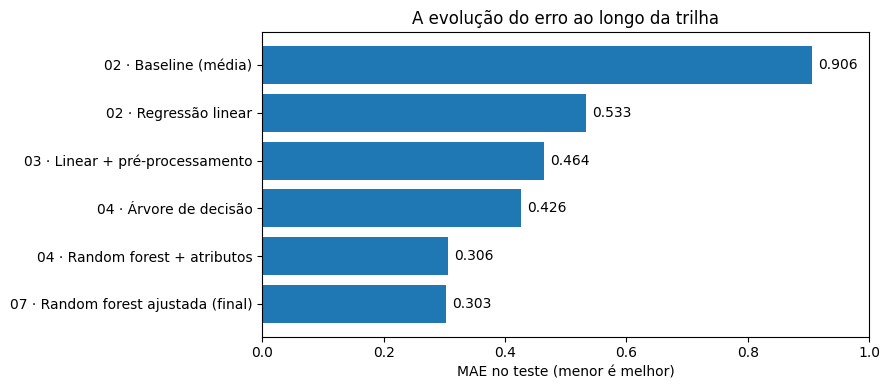

,Notebook,Modelo,MAE,R²
0,02,Baseline (média),0.906,0.000
1,02,Regressão linear,0.533,0.576
2,03,Linear + pré-processamento,0.464,0.684
3,04,Árvore de decisão,0.426,0.676
4,04,Random forest + atributos,0.306,0.826
5,07,Random forest ajustada (final),0.303,0.833


In [4]:
# A evolução de toda a trilha, no mesmo conjunto de teste.
historico = pd.DataFrame([
    {"Notebook": "02", "Modelo": "Baseline (média)",                 "MAE": 0.906, "R²": 0.000},
    {"Notebook": "02", "Modelo": "Regressão linear",                 "MAE": 0.533, "R²": 0.576},
    {"Notebook": "03", "Modelo": "Linear + pré-processamento",       "MAE": 0.464, "R²": 0.684},
    {"Notebook": "04", "Modelo": "Árvore de decisão",                "MAE": 0.426, "R²": 0.676},
    {"Notebook": "04", "Modelo": "Random forest + atributos",        "MAE": 0.306, "R²": 0.826},
    {"Notebook": "07", "Modelo": "Random forest ajustada (final)",   "MAE": round(mae, 3), "R²": round(r2, 3)},
])

fig, ax = plt.subplots(figsize=(9, 4))
rotulos = historico["Notebook"] + " · " + historico["Modelo"]   # junta os textos das duas colunas
ax.barh(rotulos, historico["MAE"])
ax.invert_yaxis()
ax.set_xlabel("MAE no teste (menor é melhor)")
ax.set_title("A evolução do erro ao longo da trilha")
for i, valor in enumerate(historico["MAE"]):
    ax.text(valor + 0.01, i, f"{valor:.3f}", va="center")
ax.set_xlim(0, 1.0)
plt.tight_layout()
plt.show()

historico

**Conclusão:** o modelo final tem **MAE de 0,303** no teste (≈ US\$ 30.300) e **R² de 0,833**: ele explica 83% da variação dos preços.

- Em relação ao **baseline**, o erro caiu **67%** (de US\$ 90.600 para US\$ 30.300).
- Em relação à primeira **regressão linear**, caiu **43%**.
- O resultado ficou muito perto da estimativa da validação cruzada do notebook 06 (0,312). Isso confirma que o processo de escolha foi **confiável**: não houve surpresa no teste.
- O ajuste de hiperparâmetros trouxe uma melhoria pequena (0,306 → 0,303), como a validação cruzada já tinha previsto.

## 4. Entendendo os erros: quanto o modelo erra?

O MAE é uma **média**, e médias escondem detalhes. Vamos olhar a **distribuição** dos erros.

In [5]:
erro_absoluto = (y_test - previsoes).abs()       # tamanho do erro de cada casa (sem sinal)
erro_relativo = erro_absoluto / y_test           # erro como fração do valor real

# Percentis: o percentil 90 é o valor abaixo do qual estão 90% dos erros.
percentis = erro_absoluto.quantile([0.5, 0.75, 0.9, 0.95])
for p, valor in percentis.items():
    print(f"{p:.0%} das casas têm erro menor que US$ {valor * 100_000:>8,.0f}")

print()
print(f"Erro relativo mediano: {erro_relativo.median():.1%} do valor da casa")
print(f"Casas com erro abaixo de 10% do valor: {(erro_relativo < 0.10).mean():.1%}")
print(f"Casas com erro abaixo de 20% do valor: {(erro_relativo < 0.20).mean():.1%}")

50% das casas têm erro menor que US$   18,330
75% das casas têm erro menor que US$   38,529
90% das casas têm erro menor que US$   72,197
95% das casas têm erro menor que US$  100,002

Erro relativo mediano: 11.0% do valor da casa
Casas com erro abaixo de 10% do valor: 46.4%
Casas com erro abaixo de 20% do valor: 72.4%


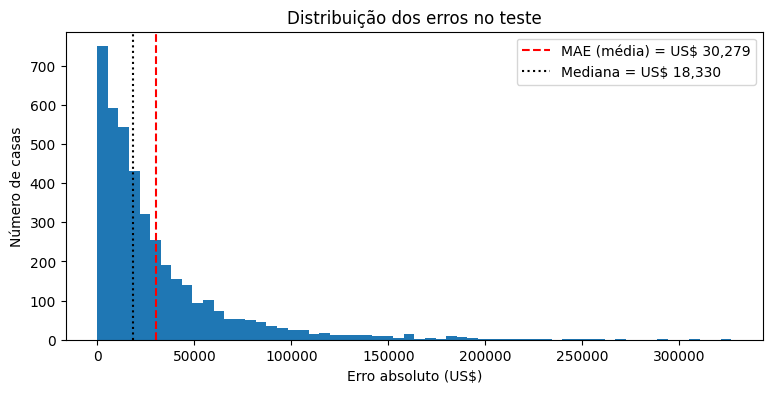

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(erro_absoluto * 100_000, bins=60)   # em dólares
ax.axvline(mae * 100_000, color="red", linestyle="--", label=f"MAE (média) = US$ {mae * 100_000:,.0f}")
ax.axvline(erro_absoluto.median() * 100_000, color="black", linestyle=":",
           label=f"Mediana = US$ {erro_absoluto.median() * 100_000:,.0f}")
ax.set_xlabel("Erro absoluto (US$)")
ax.set_ylabel("Número de casas")
ax.set_title("Distribuição dos erros no teste")
ax.legend()
plt.show()

**Conclusão:**
- Para **metade** das casas, o erro é menor que **US\$ 18.300**. A **mediana** é bem menor que a média (US\$ 30.300).
- Isso acontece porque a distribuição tem uma **cauda longa**: a maioria dos erros é pequena, mas alguns poucos são enormes (5% das casas erram mais de US\$ 100 mil). Esses poucos erros grandes "puxam" a média para cima.
- Em termos relativos, o erro típico é de **11% do valor** da casa, e 72% das casas têm erro abaixo de 20%.

**Lição:** sempre olhe a distribuição, não só a média. "Erra em média US\$ 30 mil" e "metade das casas erra menos de US\$ 18 mil" são verdades **complementares**.

## 5. Para quais casas o modelo erra mais?

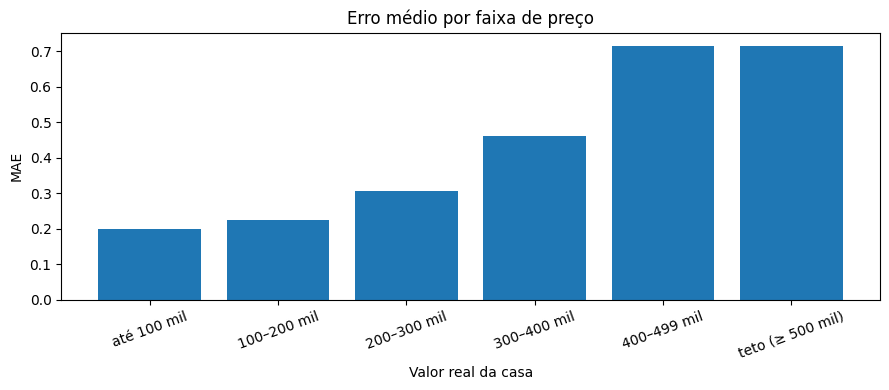

,MAE,nº de casas
faixa,,
até 100 mil,0.198,739
100–200 mil,0.224,1682
200–300 mil,0.307,956
300–400 mil,0.462,412
400–499 mil,0.716,155
teto (≥ 500 mil),0.716,184


In [7]:
# pd.cut divide os valores reais em faixas de preço (como no histograma do notebook 01).
faixas = pd.cut(
    y_test,
    bins=[0, 1, 2, 3, 4, 4.99, 5.1],
    labels=["até 100 mil", "100–200 mil", "200–300 mil", "300–400 mil", "400–499 mil", "teto (≥ 500 mil)"],
)

# groupby agrupa as casas por faixa e calcula estatísticas de cada grupo.
por_faixa = pd.DataFrame({"erro": erro_absoluto, "faixa": faixas}).groupby("faixa", observed=True)["erro"].agg(
    ["mean", "count"]
)
por_faixa.columns = ["MAE", "nº de casas"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(por_faixa.index.astype(str), por_faixa["MAE"])
ax.set_xlabel("Valor real da casa")
ax.set_ylabel("MAE")
ax.set_title("Erro médio por faixa de preço")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

por_faixa

**Conclusão:** o erro **cresce com o preço**. Nas casas de até US\$ 100 mil, o MAE é ~0,20. Nas acima de US\$ 400 mil, chega a ~0,72, mais de três vezes maior. Dois motivos:

1. **Há menos exemplos de casas caras.** Só ~8% do teste está acima de US\$ 400 mil, então o modelo tem menos dados para aprender esse padrão.
2. **O teto.** Nas casas marcadas como "5,0", o valor real é desconhecido (sabemos só que é ≥ US\$ 500 mil). Além disso, uma random forest prevê **médias**, então ela raramente chega exatamente ao extremo de 5,0.

Em termos **relativos**, porém, o erro de 0,72 numa casa de 4,5 é ~16% do valor, uma proporção parecida com o erro de 0,20 numa casa de 1,0 (~20%).

## 6. Onde no mapa o modelo erra mais?

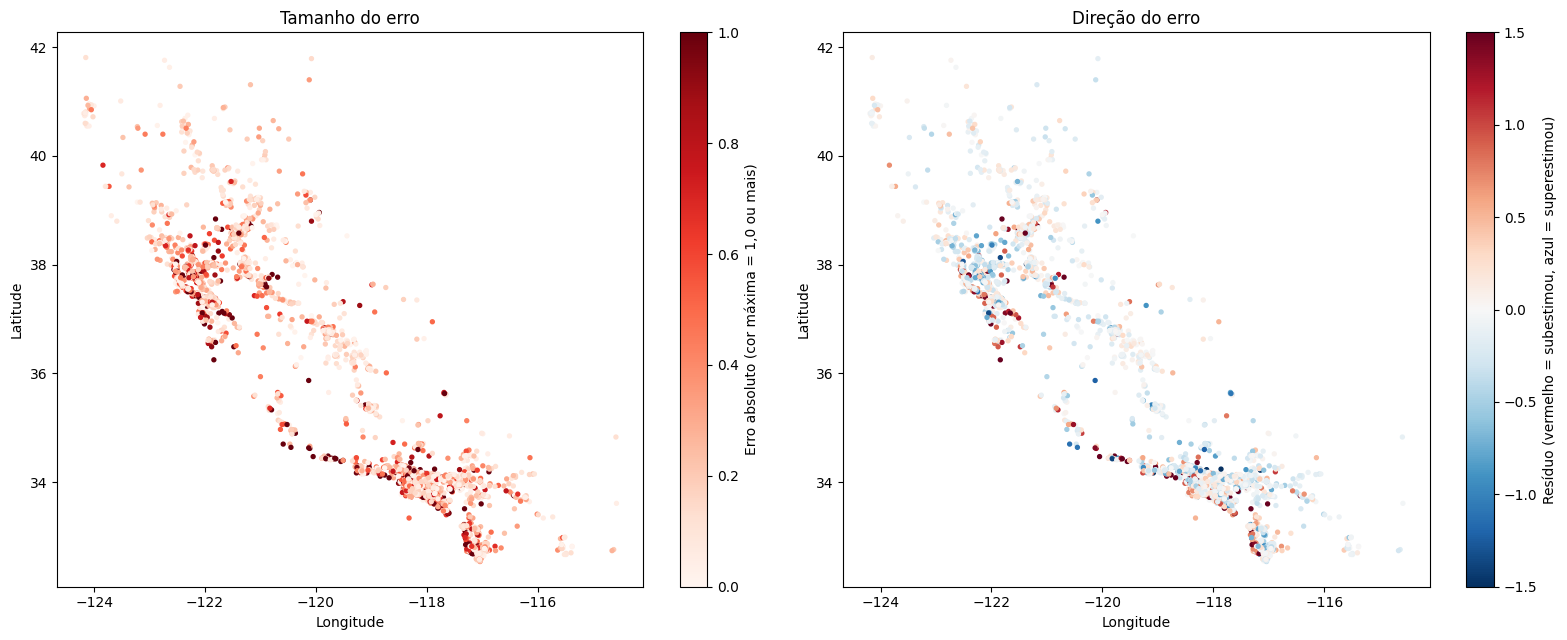

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# Mapa 1: tamanho do erro de cada casa do teste.
mapa1 = axes[0].scatter(
    X_test["Longitude"], X_test["Latitude"],
    c=erro_absoluto, cmap="Reds", s=8,
    vmax=1.0,   # erros acima de 1,0 ficam todos com a cor mais forte (evita que poucos extremos "apaguem" o resto)
)
fig.colorbar(mapa1, ax=axes[0], label="Erro absoluto (cor máxima = 1,0 ou mais)")
axes[0].set_title("Tamanho do erro")

# Mapa 2: direção do erro (resíduo = real − previsto).
#   azul     -> o modelo previu MAIS que o real (superestimou)
#   vermelho -> o modelo previu MENOS que o real (subestimou)
residuo = y_test - previsoes
mapa2 = axes[1].scatter(
    X_test["Longitude"], X_test["Latitude"],
    c=residuo, cmap="RdBu_r", s=8, vmin=-1.5, vmax=1.5,
)
fig.colorbar(mapa2, ax=axes[1], label="Resíduo (vermelho = subestimou, azul = superestimou)")
axes[1].set_title("Direção do erro")

for ax in axes:
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

**Conclusão:**
- **Os erros se concentram no litoral:** na Baía de São Francisco (latitude ~37–38), na costa de Los Angeles (~34) e em **San Diego** (~33, no extremo sul). No interior, como no Vale Central, os pontos são quase brancos: o modelo erra pouco ali.
- **Por que no litoral?** Ali os preços **variam muito em distâncias curtas**: um bairro à beira-mar pode valer o dobro de um bairro a poucos quilômetros. Além disso, é ali que estão as casas caras e as casas no teto (seção 5).
- **No mapa da direção**, o litoral mistura **vermelho** (subestimou, muitas vezes casas no teto) e **azul** (superestimou). O modelo não erra sempre para o mesmo lado: ele tem dificuldade de distinguir vizinhos com preços muito diferentes.
- **San Diego** aparece com vários pontos vermelhos fortes. Lembra que, no notebook 03, a `DistCidade` usou só São Francisco e Los Angeles, e anotamos que "há outras regiões caras (San Diego, a costa inteira)"? O mapa confirma essa limitação.

**Ideia para melhorar:** adicionar a distância até San Diego ou, melhor ainda, a **distância até o mar**. É mais engenharia de atributos, guiada pela análise de erros. Esse ciclo de "analisar os erros → ter ideias → testar" é o dia a dia de quem trabalha com ML.

## 🎓 Conceito: permutation importance

No notebook 04 vimos a importância "da árvore" (`feature_importances_`). Ela tem duas limitações:
- É calculada no **treino**, então pode dar importância a colunas que só ajudaram a **decorar** os dados.
- Tende a favorecer colunas com **muitos valores diferentes**, como `Population`, mesmo quando elas não ajudam a prever.

A **permutation importance** (importância por embaralhamento) tem uma ideia simples e poderosa:

1. Meça o erro do modelo no **teste**.
2. **Embaralhe** uma coluna, misturando seus valores entre as casas. Isso "quebra" a relação entre aquela coluna e o preço.
3. Meça o erro de novo. **Quanto mais o erro piorar, mais importante é a coluna.**

Se embaralhar uma coluna não muda nada, o modelo não dependia dela.

## 7. Permutation importance

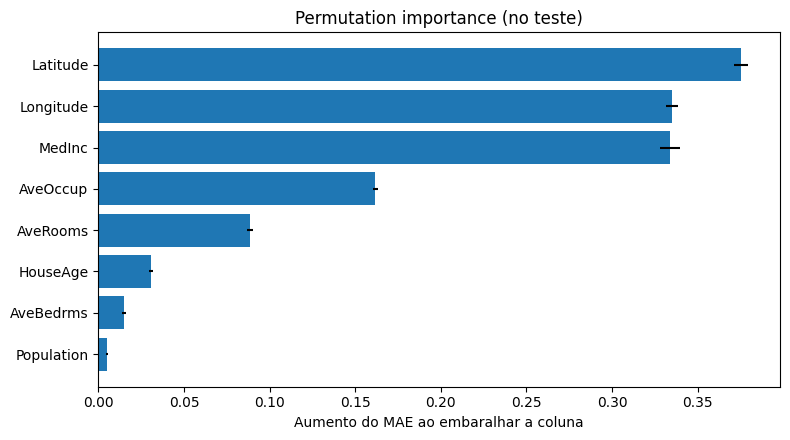

,aumento do MAE,± desvio
Latitude,0.375,0.004
Longitude,0.335,0.003
MedInc,0.334,0.006
AveOccup,0.162,0.001
AveRooms,0.088,0.002
HouseAge,0.031,0.001
AveBedrms,0.015,0.001
Population,0.005,0.001


In [9]:
# n_repeats=5: embaralha cada coluna 5 vezes (sorteios diferentes) e tira a média.
resultado_pi = permutation_importance(
    modelo_final, X_test, y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
)

# importances_mean = quanto o MAE piorou, em média, ao embaralhar cada coluna.
importancia = pd.DataFrame({
    "aumento do MAE": resultado_pi.importances_mean,
    "± desvio": resultado_pi.importances_std,
}, index=X_test.columns).sort_values("aumento do MAE")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(importancia.index, importancia["aumento do MAE"], xerr=importancia["± desvio"])
ax.set_xlabel("Aumento do MAE ao embaralhar a coluna")
ax.set_title("Permutation importance (no teste)")
plt.tight_layout()
plt.show()

importancia.sort_values("aumento do MAE", ascending=False).round(3)

**Conclusão:** embaralhar `Latitude` **dobra** o erro do modelo (MAE de 0,30 → ~0,68). `Longitude` e `MedInc` vêm logo atrás, cada uma com aumento de ~0,33.

Mas espere: no notebook 04, `MedInc` era disparada a mais importante, e `Latitude` estava lá embaixo. Por que mudou?

Repare que a permutation importance mede as colunas **originais** (as que entram no pipeline). Quando embaralhamos `Latitude`, a etapa `criar_dist_cidade` calcula a `DistCidade` usando a latitude embaralhada, então **as duas colunas se estragam juntas**. A importância de `Latitude` aqui inclui a importância da `DistCidade` (a 2ª mais importante no notebook 04). O mesmo vale para `Longitude`.

Com isso em mente, o quadro é coerente:
- **Localização** (latitude, longitude e a distância que elas formam) e **renda** são, de longe, o que mais determina o preço.
- `AveOccup` (moradores por domicílio) vem em seguida. Lembre que sua **correlação** com o preço era quase zero no notebook 01.
- `Population` quase não importa: embaralhá-la aumenta o erro em apenas 0,005.

⚠️ **Cuidado com colunas relacionadas:** se duas colunas carregam a mesma informação, embaralhar só uma pode parecer pouco importante, porque o modelo usa a outra. A importância mede **"quanto o modelo depende desta coluna"**, não **"quanto esta coluna influencia o preço no mundo real"**.

## 🎓 Conceito: dependência parcial

A importância diz **quanto** uma coluna importa, mas não **como**: o preço sobe ou desce quando ela aumenta? De forma linear, ou em curva?

O gráfico de **dependência parcial** (*partial dependence*) responde a isso:
1. Pega um valor da coluna, por exemplo renda = 5.
2. Coloca esse valor em **todas** as casas de uma amostra, mantendo as outras colunas como estão.
3. Calcula a **média** das previsões.
4. Repete para vários valores de renda e desenha a curva.

O resultado mostra o **efeito médio** de uma coluna, "descontando" as outras.

## 8. Dependência parcial

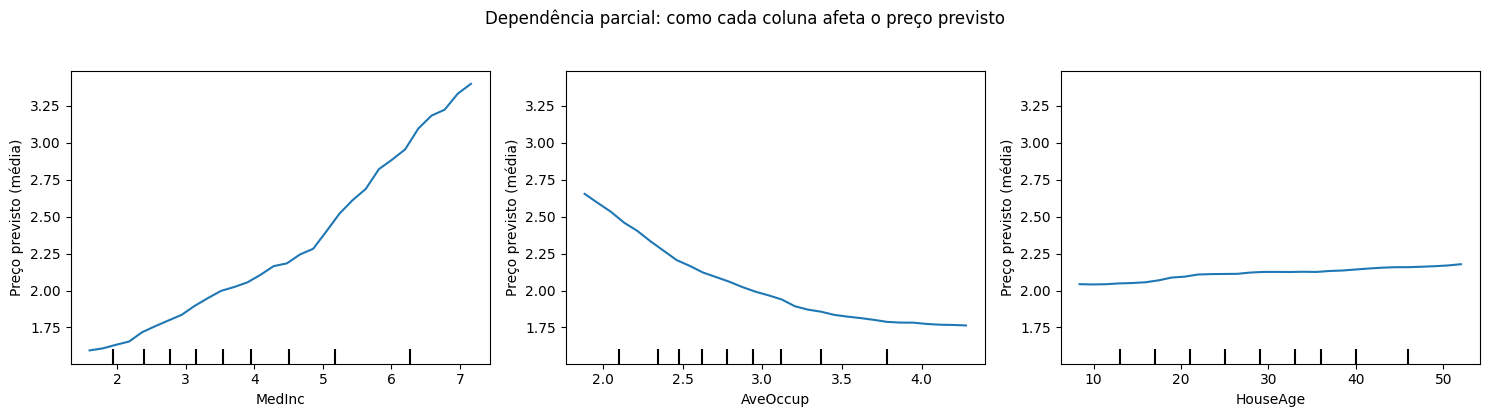

In [10]:
# Usamos uma amostra de 1.000 casas do treino para o cálculo ficar rápido.
amostra = X_train_full.sample(1000, random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
PartialDependenceDisplay.from_estimator(
    modelo_final, amostra,
    features=["MedInc", "AveOccup", "HouseAge"],   # colunas a analisar
    ax=axes,
    grid_resolution=30,   # quantos valores de cada coluna testar
)
for ax in axes:
    ax.set_ylabel("Preço previsto (média)")
fig.suptitle("Dependência parcial: como cada coluna afeta o preço previsto", y=1.03)
plt.tight_layout()
plt.show()

*Como ler:* o eixo y é o preço previsto médio quando a coluna do eixo x assume aquele valor. Os tracinhos no rodapé marcam os **decis** dos dados (a cada 10% das casas). Onde há poucos tracinhos, há poucos dados, e a curva é menos confiável.

**Conclusão:**
- **`MedInc` (renda):** o preço previsto sobe de ~1,6 para ~3,4 conforme a renda vai de 1,6 para 7,2. A curva fica **mais inclinada** a partir de renda ~5: em regiões mais ricas, cada aumento de renda "vale mais". Uma reta (notebook 02) não captura essa aceleração.
- **`AveOccup` (moradores por domicílio):** quanto **mais** moradores, **mais barato**: de ~2,65 com 2 moradores para ~1,8 com 4. O efeito é forte no começo e se **estabiliza** acima de ~3,5. Domicílios lotados indicam regiões onde as pessoas dividem casa para conseguir pagar a moradia. Lembre que a correlação linear desta coluna com o preço era quase **zero** (notebook 01): a relação existe, mas é curva, e a correlação de Pearson não a enxerga.
- **`HouseAge` (idade das casas):** a curva é quase **plana** (de 2,05 para 2,18). Mantendo as outras colunas iguais, a idade das casas quase não muda o preço previsto. Isso combina com a baixa importância dela na seção 7.

⚠️ A dependência parcial mostra o **efeito médio**. Ela pode esconder efeitos que mudam de uma região para outra (por exemplo, casas antigas podem ser valorizadas em San Francisco e desvalorizadas em outro lugar).

## 9. Salvando o modelo

Treinar o modelo leva alguns segundos aqui, mas em projetos reais pode levar horas. E, na prática, o modelo é **usado** em outro lugar: num site, num aplicativo, num script. Por isso salvamos o modelo treinado num **arquivo**, que pode ser carregado depois **sem treinar de novo**.

O `joblib` transforma o objeto Python (o pipeline inteiro, com as 100 árvores) num arquivo. Esse processo se chama **serialização**.

In [11]:
# Path cria um "caminho" de arquivo. mkdir cria a pasta (exist_ok=True: sem erro se já existir).
pasta_modelos = Path("modelos")
pasta_modelos.mkdir(exist_ok=True)
caminho = pasta_modelos / "random_forest_final.joblib"   # "/" junta pastas e nomes de arquivo

# compress=3 comprime o arquivo (mais lento para salvar, mas bem menor).
joblib.dump(modelo_final, caminho, compress=3)

tamanho_mb = caminho.stat().st_size / 1_000_000
print(f"Modelo salvo em: {caminho}  ({tamanho_mb:.0f} MB)")

Modelo salvo em: modelos/random_forest_final.joblib  (33 MB)


**Conclusão:** mesmo comprimido, o arquivo tem ~33 MB (sem compressão, seriam ~145 MB). As 100 árvores **sem limite de profundidade** têm milhares de folhas cada uma, e todas precisam ser guardadas.

Por isso a pasta `modelos/` está no `.gitignore`: arquivos grandes não devem ir para o Git (o GitHub recusa arquivos acima de 100 MB). Quem clonar o projeto recria o modelo rodando este notebook. Em projetos reais, modelos ficam em serviços próprios para isso, como o *MLflow*, ou num armazenamento na nuvem.

⚠️ **Por que criamos o `atributos.py`?** O arquivo salvo **não guarda o código** das funções `criar_derivados` e `criar_dist_cidade`. Ele guarda só o **nome** delas e **onde encontrá-las** ("a função `criar_derivados` do módulo `atributos`"). Se elas fossem definidas dentro do notebook, como nos notebooks anteriores, o arquivo diria "a função está no notebook". Aí qualquer outro programa que tentasse carregar o modelo daria erro, porque não teria acesso ao notebook.

Para provar que funciona, vamos carregar o modelo num **processo Python totalmente separado**, como se fosse outro programa.

In [12]:
# Um pequeno programa Python, escrito como texto, que carrega o modelo e prevê 3 casas.
programa = f'''
import joblib
from sklearn.datasets import fetch_california_housing

modelo = joblib.load("{caminho}")
X = fetch_california_housing(as_frame=True).frame.drop(columns="MedHouseVal")
print("Modelo carregado! Previsões para as 3 primeiras casas:", modelo.predict(X.head(3)).round(3))
'''

# subprocess.run executa um comando como se fosse no terminal.
# sys.executable é o caminho do Python que está rodando este notebook (o do .venv).
saida = subprocess.run([sys.executable, "-c", programa], capture_output=True, text=True)
print(saida.stdout or saida.stderr)

# Comparando com o modelo que está na memória deste notebook:
print("Previsões do modelo original:                    ", modelo_final.predict(X.head(3)).round(3))

Modelo carregado! Previsões para as 3 primeiras casas: [4.304 3.867 3.789]

Previsões do modelo original:                     [4.304 3.867 3.789]


**Conclusão:** o outro processo carregou o arquivo e fez **exatamente as mesmas previsões**, sem treinar nada e sem acesso a este notebook. Ele só precisou do arquivo `.joblib` e do `atributos.py`.

## 10. Prevendo o preço de casas novas

Este é o objetivo final de um modelo: **prever casos que ainda não existem nos dados**. Vamos imaginar dois blocos censitários:
- **Bloco A:** perto de Palo Alto (Vale do Silício), região rica.
- **Bloco B:** perto de Fresno, no interior agrícola do estado.

Lembre que cada linha é um **bloco**, não uma casa individual. Por isso as colunas são médias e medianas.

In [13]:
# Lemos o modelo do arquivo, como faria um sistema que usa o modelo no dia a dia.
modelo_carregado = joblib.load(caminho)

# Cada dicionário é uma linha; a lista de dicionários vira uma tabela.
blocos_novos = pd.DataFrame([
    {"MedInc": 8.0, "HouseAge": 30, "AveRooms": 6.0, "AveBedrms": 1.05,
     "Population": 1200, "AveOccup": 2.6, "Latitude": 37.45, "Longitude": -122.15},
    {"MedInc": 3.0, "HouseAge": 20, "AveRooms": 5.5, "AveBedrms": 1.10,
     "Population": 1500, "AveOccup": 3.2, "Latitude": 36.75, "Longitude": -119.75},
], index=["A · Palo Alto", "B · Fresno"])

blocos_novos

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
A · Palo Alto,8.0,30,6.0,1.05,1200,2.6,37.45,-122.15
B · Fresno,3.0,20,5.5,1.10,1500,3.2,36.75,-119.75


In [14]:
precos = modelo_carregado.predict(blocos_novos)

# Bônus: cada uma das 100 árvores dá o seu palpite. A variação entre os palpites
# dá uma ideia de quão "segura" é a previsão.
floresta = modelo_carregado["modelo"]
X_transformado = modelo_carregado[:-1].transform(blocos_novos)   # aplica as etapas de atributos
palpites = np.array([arvore.predict(X_transformado.values) for arvore in floresta.estimators_])

# np.percentile(..., axis=0) calcula o percentil de cada COLUNA (cada bloco).
p10 = np.percentile(palpites, 10, axis=0)
p90 = np.percentile(palpites, 90, axis=0)

for nome, preco, baixo, alto in zip(blocos_novos.index, precos, p10, p90):
    print(f"{nome}: US$ {preco * 100_000:>8,.0f}   "
          f"(80% das árvores entre US$ {baixo * 100_000:,.0f} e US$ {alto * 100_000:,.0f})")

A · Palo Alto: US$  440,553   (80% das árvores entre US$ 360,410 e US$ 500,001)
B · Fresno: US$   77,832   (80% das árvores entre US$ 65,790 e US$ 92,410)


**Conclusão:**
- **Bloco A (Palo Alto):** ≈ **US\$ 440 mil**. Renda alta e localização perto de São Francisco levam a um preço próximo do teto.
- **Bloco B (Fresno):** ≈ **US\$ 78 mil**. Renda menor e distância das grandes cidades.

Repare na **faixa** das árvores. No bloco A, ela é larga (de ~US\$ 360 mil até o teto de US\$ 500 mil): as árvores discordam mais, porque casas caras são raras e o teto confunde. No bloco B, a faixa é estreita (~US\$ 66–92 mil): há muitos exemplos parecidos no treino, e as árvores concordam.

⚠️ Essa faixa **não é** um intervalo de confiança estatístico rigoroso. É só uma indicação de **concordância** entre as árvores. Mesmo assim, é uma informação útil: uma previsão em que o próprio modelo "hesita" merece mais cautela.

## 11. Limitações e uso responsável

Um bom cientista de dados sabe dizer o que o modelo **não** faz. Antes de usar este modelo para qualquer decisão real, considere:

1. **Os dados são de 1990.** Os preços de hoje são muito maiores (por inflação e pela valorização do mercado), e a geografia econômica da Califórnia mudou. O modelo aprendeu padrões de **35 anos atrás**.
2. **Cada linha é um bloco censitário, não uma casa.** O modelo prevê o valor **mediano** de uma região, não o preço de um imóvel específico. Ele não sabe nada sobre o estado de conservação, a vista ou a reforma de uma casa.
3. **O teto em US\$ 500 mil.** O modelo nunca vai prever acima disso e erra mais nas regiões caras.
4. **Erros grandes existem.** 5% das casas têm erro acima de US\$ 100 mil. Um MAE bom não garante acerto em cada caso.
5. **Viés histórico.** Modelos aprendem os padrões do passado, **inclusive as desigualdades**. Se um modelo assim fosse usado, por exemplo, para aprovar crédito ou definir seguros, ele poderia reforçar diferenças históricas entre regiões. Usar a localização como atributo exige cuidado e discussão.

Este é um ótimo dataset para **aprender** Machine Learning, mas o modelo não deve ser usado para avaliar imóveis de verdade.

## 12. Resumo da trilha

**O que você aprendeu nos 7 notebooks**

| Notebook | Conceitos principais |
|---|---|
| 01 | Análise exploratória: distribuições, outliers, correlação, mapas |
| 02 | Aprendizado supervisionado, treino/teste, baseline, MAE/RMSE/R², regressão linear, resíduos |
| 03 | Validação, padronização, vazamento de dados, Pipeline, engenharia de atributos, logaritmo |
| 04 | Árvores de decisão, overfitting, hiperparâmetros, random forest, ensemble, importância |
| 05 | Validação cruzada K-Fold, média ± desvio, comparação pareada |
| 06 | Grid search, random search, maldição do vencedor |
| 07 | Avaliação final, análise de erros, permutation importance, dependência parcial, salvar modelos, uso responsável |

**Neste notebook, especificamente:**
- Treinar o **modelo final** com todos os dados de treino e avaliar no teste **uma única vez**.
- Olhar a **distribuição** dos erros (mediana × média, percentis, erro relativo).
- Analisar os erros **por faixa** e **no mapa**.
- **Permutation importance** e o cuidado com colunas relacionadas.
- **Dependência parcial**: o efeito médio de cada coluna.
- **Serialização** com `joblib` e por que as funções precisam estar num módulo (`atributos.py`).
- Prever casos novos e medir a **concordância entre as árvores**.

**Python novo:** `pathlib.Path`, `subprocess`, `sys.executable`, `groupby`, `.agg` e `np.percentile(..., axis=0)`.

**Resultado final:** de um baseline com erro de US\$ 90.600 para um modelo com **US\$ 30.300** de erro médio e **R² de 0,83**.

**Próximos passos (opcionais):**
- **Notebook 08: gradient boosting.** Árvores que corrigem os erros umas das outras, normalmente o modelo mais forte para dados em tabela, e muito sensível aos hiperparâmetros (o notebook 06 vai fazer falta!).
- **Notebook 09: regularização.** `Ridge` e `Lasso` voltam à regressão linear para tratar a multicolinearidade vista desde o notebook 02.